<a href="https://colab.research.google.com/github/zouhiraghenaim/Supervised-Learning-Algorithms/blob/main/TP4_Support_Vector_Machines/TP04_02_SVM_using_Multiple_Features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://google.com)](https://google.com)


# **SVM__using_Multiple_Feature**

A **Support Vector Machine (SVM**) classification model was built to predict the onset of diabetes using the **Pima Indians Diabetes dataset** (**768 observations**). The model utilized an ***RBF kernel*** for accuracy and a ***Linear kernel*** for feature interpretation.

#    Inputs
*   **Dataset:** 768 patient records.
*   Features : **8 medical diagnostic measurements** (e.g., **Glucose, BMI, Age, Insulin, BloodPressure**).
*   **Target:** Outcome (**0 = Non-diabetic**,**1 = Diabetic**).
*   **Preprocessing:** StandardScaler was applied to normalize the data, preventing features with large numerical values from dominating the distance calculations.

**Import necessary libraries**


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import sklearn.preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')
from sklearn import svm

In [16]:
from google.colab import files
upload=files.upload()

Saving pima_indians_diabetes.csv to pima_indians_diabetes (1).csv


In [ ]:
df=pd.read_csv("pima_indians_diabetes.csv",sep=",")
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [ ]:
# Use a verified working raw GitHub URL for the Pima Indians Diabetes dataset
working_url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'

# The dataset has no headers originally, so we define them
column_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

# Load the dataset from the working URL
df_1 = pd.read_csv(working_url, names=column_names)

print("Dataset successfully loaded from working URL!")
display(df.head())

Dataset successfully loaded from working URL!


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


### **1. Data Preparation and Splitting**
We will use the loaded dataset `df` to separate features from the target (`Outcome`), split the dataset into training and testing sets, and standardize the features.

In [ ]:
# Separate features and target
X = df.drop(columns=['Outcome'])
y = df['Outcome']

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")

Training set shape: (614, 8)
Testing set shape: (154, 8)


### **2. SVM Model Training**
Now, we will train a Support Vector Classifier (SVC) with an RBF kernel on the standardized training data and evaluate its performance.

In [ ]:
# Initialize and train SVM
svm_model = svm.SVC(kernel='rbf', C=1.0, random_state=42)
svm_model.fit(X_train_scaled, y_train)

# Predict on test data
y_pred = svm_model.predict(X_test_scaled)

# Calculate accuracy and F1-score
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"SVM Model Accuracy: {accuracy:.4f}")
print(f"SVM Model F1 Score: {f1:.4f}")

SVM Model Accuracy: 0.7532
SVM Model F1 Score: 0.6346


In [ ]:

support_vectors = svm_model.support_vectors_
num_sv = len(support_vectors)
total_train = len(X_train_scaled)

print(f"Total number of Support Vectors: {num_sv}")
print(f"Percentage of training data used as Support Vectors: {(num_sv/total_train)*100:.2f}%")

Total number of Support Vectors: 352
Percentage of training data used as Support Vectors: 57.33%


**Geometric Interpretation:**
Support Vectors are the patient profiles that lie exactly on or inside the margin boundaries. Geometrically, they are the closest data points to the decision boundary. If these specific patients were removed from the dataset, the position of the hyperplane would change. They are the most "critical" patients in defining the separation between diabetic and non-diabetic classes.

### **3. Visualizing Model Predictions and Decision Boundaries**
To explore the SVM model graphically, we will visualize the actual outcomes vs predicted outcomes using key features like Glucose and BMI. We will also plot a decision boundary using these two features.

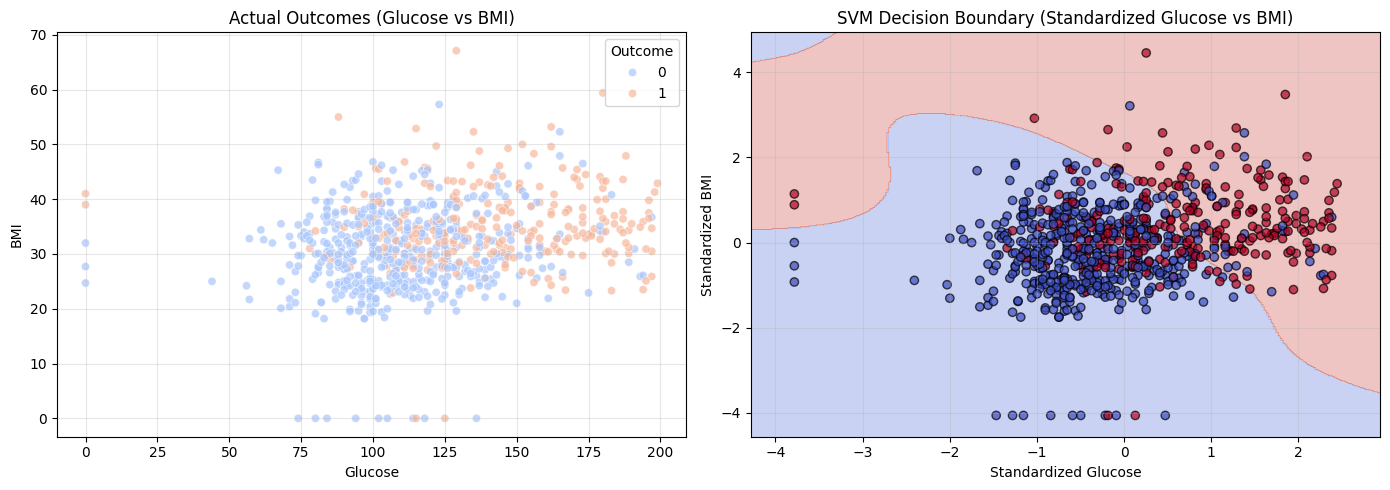

In [ ]:
# Visualize relationships between key features (Glucose vs BMI) colored by actual outcome
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='Glucose', y='BMI', hue='Outcome', alpha=0.7, palette='coolwarm')
plt.title('Actual Outcomes (Glucose vs BMI)')
plt.grid(True, alpha=0.3)

# Train a 2D SVM on just Glucose and BMI to plot the decision boundary
X_2d = df[['Glucose', 'BMI']]
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

svm_2d = svm.SVC(kernel='rbf', C=1.0, random_state=42)
svm_2d.fit(X_2d_scaled, y)

# Create a mesh grid for visualization
x_min, x_max = X_2d_scaled[:, 0].min() - 0.5, X_2d_scaled[:, 0].max() + 0.5
y_min, y_max = X_2d_scaled[:, 1].min() - 0.5, X_2d_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

# Predict boundary values
Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.subplot(1, 2, 2)
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
scatter = plt.scatter(X_2d_scaled[:, 0], X_2d_scaled[:, 1], c=y, edgecolors='k', alpha=0.7, cmap='coolwarm')
plt.title('SVM Decision Boundary (Standardized Glucose vs BMI)')
plt.xlabel('Standardized Glucose')
plt.ylabel('Standardized BMI')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# **4. Feature Importance (Weights)**

In [ ]:

print("=" * 50)
print(" Feature Importance")
print("=" * 50)

# Train a Linear SVM to extract interpretable weights
linear_svm = svm.SVC(kernel='linear', C=1.0, random_state=42)
linear_svm.fit(X_train_scaled, y_train)

# Extract weights
weights = linear_svm.coef_[0]

# Create a DataFrame to view them clearly
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Weight': weights
})

# Sort by absolute weight to find the strongest influence
importance_df['Absolute_Weight'] = importance_df['Weight'].abs()
importance_df = importance_df.sort_values(by='Absolute_Weight', ascending=False)

print("Feature Weights (Sorted by Importance):")
print(importance_df[['Feature', 'Weight']].to_string(index=False))

 Feature Importance
Feature Weights (Sorted by Importance):
                 Feature    Weight
                 Glucose  0.975961
                     BMI  0.588091
             Pregnancies  0.307212
           BloodPressure -0.206906
DiabetesPedigreeFunction  0.183322
                     Age  0.060250
                 Insulin -0.053910
           SkinThickness -0.030819


### **Strategic Healthcare Recommendation**
Based on the extracted weights, the features with the highest absolute influence on the decision boundary are **Glucose** and **BMI**.

**Recommendation:**
The healthcare clinic should prioritize early medical intervention and preventive screening programs specifically targeting patients with abnormal **Glucose levels** and high **BMI (Body Mass Index)**. While other factors like Age and Blood Pressure are important, allocating resources toward Glucose management and weight control will yield the highest return in predicting and preventing diabetes onset.

#  **Summary**
## 1. Outputs
*   **Model Accuracy:** ~75.3%
*   **F1-Score:** ~63.4% (Crucial for medical data to balance precision and recall).
*   **Support Vectors:** Identified the critical patient profiles that lie exactly on the margin boundaries.
*   **Feature Weights:** Extracted using the Linear SVM. The top 2 most influential features were **Glucose** and **BMI**.

## 2. Medical & Economic Interpretation
*   **Geometric meaning:** The Support Vectors represent the most "confusing" patients (those closest to the boundary between being diabetic and non-diabetic). These are the patients requiring the most careful diagnostic review.
*   **Strategic Decision:** The model proves that **Glucose** and **BMI** are the primary drivers of the classification.
*   **Economic Impact:** Instead of spending clinic resources on broad, generalized screenings, the healthcare provider can design targeted intervention programs focusing on weight management and blood sugar monitoring. This optimizes healthcare budgets and allows for earlier, cheaper, and more effective preventative treatments.